# ChestScan AI — Classification des radiographies thoraciques

Ce notebook compare deux modèles pour classifier les images en **NORMAL** et **PNEUMONIA** :
1. un CNN construit from scratch ;
2. MobileNetV2 avec Transfer Learning.

> Ce projet est pédagogique. Il ne doit pas être utilisé pour établir un diagnostic médical.

## 1. Installer les dépendances

Exécute cette cellule si certaines bibliothèques ne sont pas installées.

In [1]:
%pip install -q kagglehub tensorflow numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Imports et configuration

In [22]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

SEED = 42
IMG_SIZE_CNN = (180, 180)
IMG_SIZE_MOBILENET = (224, 224)
BATCH_SIZE = 32
EPOCHS_CNN = 15
EPOCHS_MOBILENET = 5
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.19.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Télécharger et localiser le dataset

Le dataset public est téléchargé via KaggleHub. Si Kaggle demande une authentification, configure tes identifiants Kaggle puis relance cette cellule.

In [ ]:
dataset_path = Path(
    kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
)
print("Chemin téléchargé :", dataset_path)

# Cherche un dossier qui contient train, val et test.
candidate_dirs = [dataset_path]
candidate_dirs.extend(dataset_path.rglob("chest_xray"))
candidate_dirs.extend(dataset_path.rglob("chest-xray-pneumonia"))

DATASET_ROOT = None
seen = set()

for folder in candidate_dirs:
    folder = Path(folder)
    if str(folder) in seen:
        continue
    seen.add(str(folder))
    if all((folder / split).is_dir() for split in ["train", "val", "test"]):
        DATASET_ROOT = folder
        break

if DATASET_ROOT is None:
    # Certains téléchargements ont un niveau supplémentaire de dossiers.
    for folder in dataset_path.rglob("*"):
        if folder.is_dir() and all(
            (folder / split).is_dir() for split in ["train", "val", "test"]
        ):
            DATASET_ROOT = folder
            break

if DATASET_ROOT is None:
    raise FileNotFoundError(
        f"Impossible de trouver les dossiers train/val/test dans {dataset_path}. "
        "Inspecte le chemin téléchargé et vérifie la structure du dataset."
    )

for split in ["train", "val", "test"]:
    for class_name in CLASS_NAMES:
        class_dir = DATASET_ROOT / split / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Dossier manquant : {class_dir}")

print("DATASET_ROOT =", DATASET_ROOT)

100%|██████████| 2.29G/2.29G [01:09<00:00, 35.4MB/s]

Extracting files...


Chemin téléchargé : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2
DATASET_ROOT = /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray


## 4. Explorer la distribution des images

In [4]:
extensions = {".jpeg", ".jpg", ".png"}
rows = []

for split in ["train", "val", "test"]:
    for class_name in CLASS_NAMES:
        folder = DATASET_ROOT / split / class_name
        count = sum(
            1 for file in folder.rglob("*")
            if file.is_file() and file.suffix.lower() in extensions
        )
        rows.append({
            "Split": split,
            "Classe": class_name,
            "Nombre d'images": count
        })

df_counts = pd.DataFrame(rows)
display(df_counts)
print("Total des images :", int(df_counts["Nombre d'images"].sum()))

,Split,Classe,Nombre d'images
0,train,NORMAL,1341
1,train,PNEUMONIA,3875
2,val,NORMAL,8
3,val,PNEUMONIA,8
4,test,NORMAL,234
5,test,PNEUMONIA,390


Total des images : 5856


## 5. Charger les datasets

Les labels sont 0 pour NORMAL et 1 pour PNEUMONIA. Les pixels restent en valeurs brutes ici : le CNN les normalise dans son modèle et MobileNetV2 utilise son propre prétraitement.

In [ ]:
def create_dataset(directory, image_size, shuffle):
    return keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="binary",
        class_names=CLASS_NAMES,
        image_size=image_size,
        batch_size=BATCH_SIZE,
        color_mode="rgb",
        shuffle=shuffle,
        seed=SEED,
    )

train_ds_cnn = create_dataset(DATASET_ROOT / "train", IMG_SIZE_CNN, True)
val_ds_cnn = create_dataset(DATASET_ROOT / "val", IMG_SIZE_CNN, False)
test_ds_cnn = create_dataset(DATASET_ROOT / "test", IMG_SIZE_CNN, False)

train_ds_mobilenet = create_dataset(
    DATASET_ROOT / "train", IMG_SIZE_MOBILENET, True
)
val_ds_mobilenet = create_dataset(
    DATASET_ROOT / "val", IMG_SIZE_MOBILENET, False
)
test_ds_mobilenet = create_dataset(
    DATASET_ROOT / "test", IMG_SIZE_MOBILENET, False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds_cnn = train_ds_cnn.prefetch(AUTOTUNE)
val_ds_cnn = val_ds_cnn.prefetch(AUTOTUNE)
test_ds_cnn = test_ds_cnn.prefetch(AUTOTUNE)
train_ds_mobilenet = train_ds_mobilenet.prefetch(AUTOTUNE)
val_ds_mobilenet = val_ds_mobilenet.prefetch(AUTOTUNE)
test_ds_mobilenet = test_ds_mobilenet.prefetch(AUTOTUNE)

print("Classes :", CLASS_NAMES)

Found 5216 files belonging to 2 classes.


I0000 00:00:1792668086.896677     817 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 18312 MB memory:  -> device: 0, name: NVIDIA RTX 4000 SFF Ada Generation, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes : ['NORMAL', 'PNEUMONIA']


In [17]:
images, labels = next(iter(train_ds_cnn))
plt.figure(figsize=(12, 8))

print(images.shape)

(32, 180, 180, 3)


<Figure size 1200x800 with 0 Axes>

## 6. Visualiser quelques images

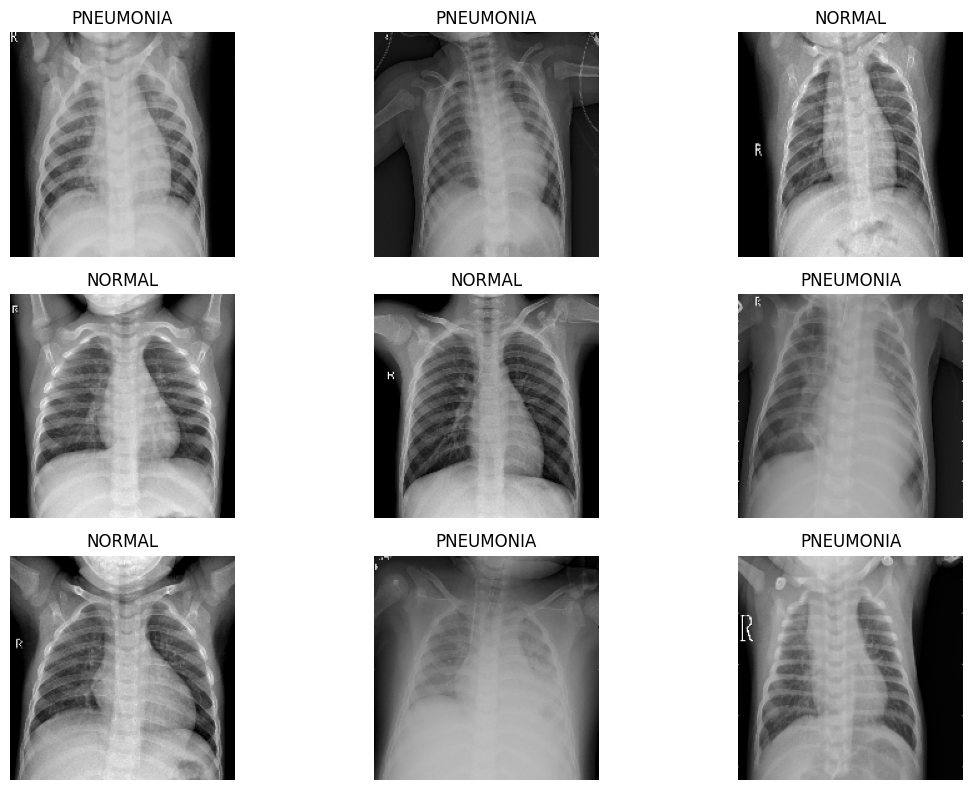

In [24]:
images, labels = next(iter(train_ds_cnn))
plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(labels[i].numpy()[0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Construire le CNN from scratch

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")

cnn_model = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE_CNN, 3)),
    data_augmentation,
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
], name="CNN_From_Scratch")

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
cnn_model.summary()

Model: "CNN_From_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,769 (15.22 MB)

 Trainable params: 3,988,769 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Entraîner le CNN

In [8]:
os.makedirs("outputs", exist_ok=True)

cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "outputs/best_cnn.keras", monitor="val_loss", save_best_only=True
    ),
]

history_cnn = cnn_model.fit(
    train_ds_cnn,
    validation_data=val_ds_cnn,
    epochs=EPOCHS_CNN,
    callbacks=cnn_callbacks,
)

Epoch 1/15


I0000 00:00:1792668092.740741     986 cuda_dnn.cc:529] Loaded cuDNN version 90300


163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.7366 - auc: 0.6413 - loss: 0.6011 - precision: 0.7608 - recall: 0.9385 - val_accuracy: 0.8125 - val_auc: 0.9531 - val_loss: 0.4553 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9122 - auc: 0.9587 - loss: 0.2311 - precision: 0.9303 - recall: 0.9518 - val_accuracy: 0.8125 - val_auc: 0.9531 - val_loss: 0.4036 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9216 - auc: 0.9660 - loss: 0.2076 - precision: 0.9406 - recall: 0.9534 - val_accuracy: 0.7500 - val_auc: 0.9844 - val_loss: 0.5755 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9259 - auc: 0.9699 - loss: 0.1937 - precision: 0.9458 - recall: 0.9533 - val_accuracy: 0.7500 - val_auc: 0.9688 - val_loss: 0.6439 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━

## 9. Visualiser l'entraînement du CNN

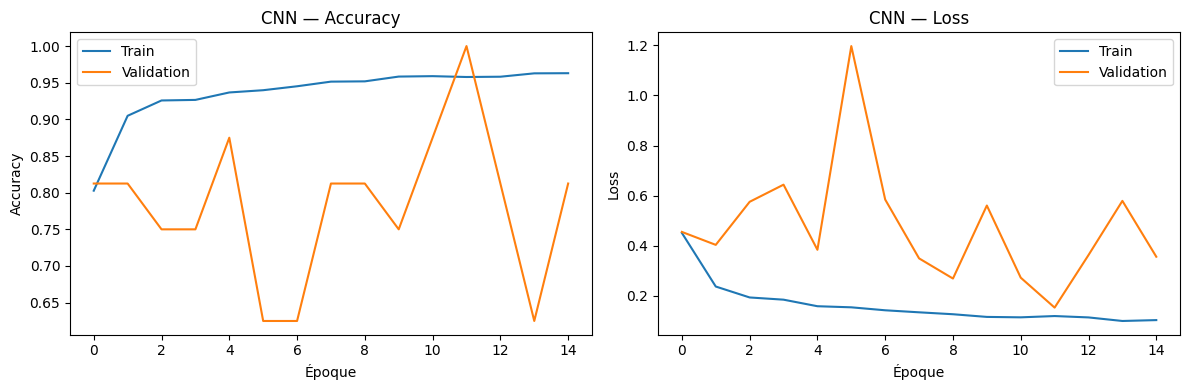

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Train")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("CNN — Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Train")
plt.plot(history_cnn.history["val_loss"], label="Validation")
plt.title("CNN — Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Construire MobileNetV2 avec Transfer Learning

Les poids ImageNet de la base sont gelés pendant cette première phase. La tête de classification ajoutée apprend à distinguer les deux classes.

In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE_MOBILENET, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE_MOBILENET, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

mobilenet_model = keras.Model(
    inputs, outputs, name="MobileNetV2_Transfer_Learning"
)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV2_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11. Entraîner MobileNetV2

In [11]:
mobilenet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "outputs/best_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True,
    ),
]

history_mobilenet = mobilenet_model.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    epochs=EPOCHS_MOBILENET,
    callbacks=mobilenet_callbacks,
)

Epoch 1/5


I0000 00:00:1792668139.919236     990 service.cc:152] XLA service 0x7f32a000b190 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792668139.919272     990 service.cc:160]   StreamExecutor device (0): NVIDIA RTX 4000 SFF Ada Generation, Compute Capability 8.9
2026-10-22 11:22:20.018366: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


 10/163 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6161 - auc: 0.6454 - loss: 0.6763 - precision: 0.7846 - recall: 0.5860

I0000 00:00:1792668143.765812     990 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


163/163 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.8229 - auc: 0.8569 - loss: 0.3888 - precision: 0.8525 - recall: 0.9140 - val_accuracy: 0.8750 - val_auc: 0.9688 - val_loss: 0.2915 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9589 - auc: 0.9886 - loss: 0.1379 - precision: 0.9688 - recall: 0.9755 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2544 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9667 - auc: 0.9922 - loss: 0.1081 - precision: 0.9766 - recall: 0.9780 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2116 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9685 - auc: 0.9944 - loss: 0.0934 - precision: 0.9798 - recall: 0.9773 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2383 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s

## 12. Visualiser l'entraînement de MobileNetV2

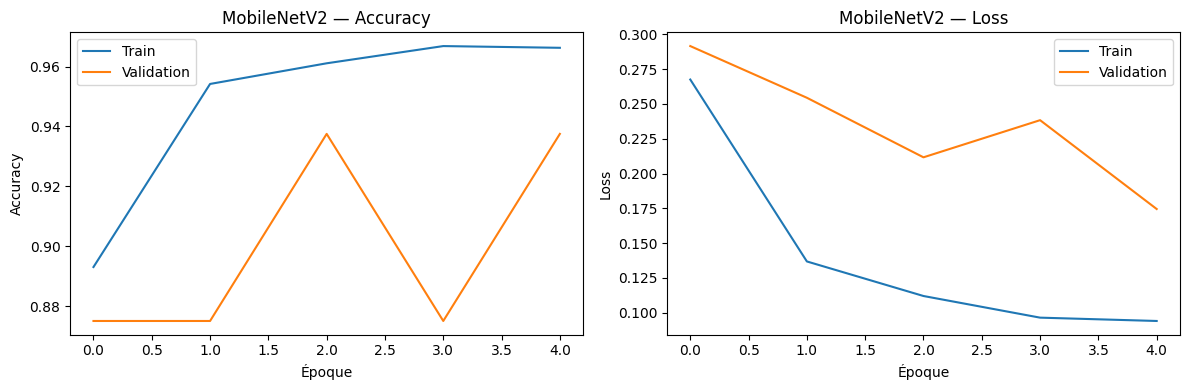

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Train")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 — Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Train")
plt.plot(history_mobilenet.history["val_loss"], label="Validation")
plt.title("MobileNetV2 — Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 13. Évaluer et comparer les modèles

Les métriques sont calculées sur le jeu de test. Les prédictions positives correspondent à la classe PNEUMONIA.

2026-10-22 11:22:43.179788: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



===== CNN from scratch =====
              precision    recall  f1-score   support

      NORMAL       0.96      0.60      0.74       234
   PNEUMONIA       0.80      0.98      0.88       390

    accuracy                           0.84       624
   macro avg       0.88      0.79      0.81       624
weighted avg       0.86      0.84      0.83       624



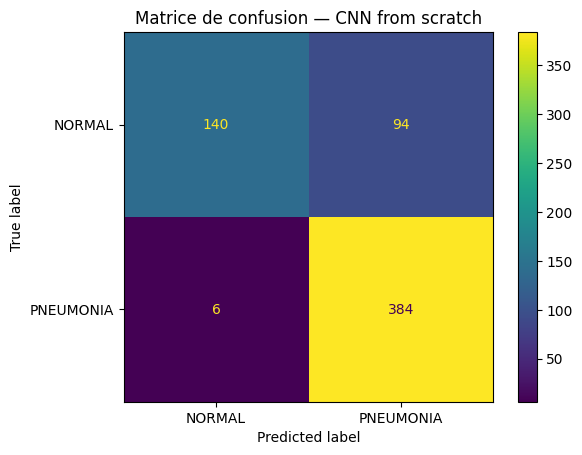

2026-10-22 11:22:43.760127: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



===== MobileNetV2 =====
              precision    recall  f1-score   support

      NORMAL       0.98      0.54      0.70       234
   PNEUMONIA       0.78      0.99      0.88       390

    accuracy                           0.82       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.86      0.82      0.81       624



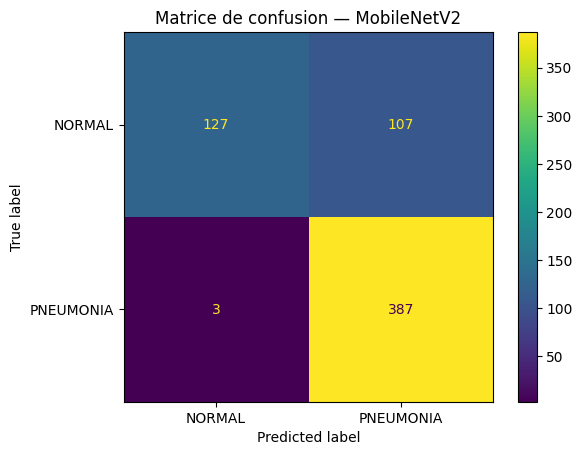

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
CNN from scratch,0.8397,0.8033,0.9846,0.8848,0.9495
MobileNetV2,0.8237,0.7834,0.9923,0.8756,0.9638


In [13]:
def evaluate_classifier(model, dataset, model_name):
    y_true = np.concatenate([
        labels.numpy().reshape(-1) for _, labels in dataset
    ]).astype(int)

    y_prob = model.predict(dataset, verbose=0).reshape(-1)
    y_pred = (y_prob >= 0.5).astype(int)

    result = {
        "Modèle": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

    print(f"\n===== {model_name} =====")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        zero_division=0,
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=CLASS_NAMES
    )
    display_cm.plot(values_format="d")
    plt.title(f"Matrice de confusion — {model_name}")
    plt.show()

    return result

results_cnn = evaluate_classifier(cnn_model, test_ds_cnn, "CNN from scratch")
results_mobilenet = evaluate_classifier(
    mobilenet_model, test_ds_mobilenet, "MobileNetV2"
)

comparison_df = pd.DataFrame([results_cnn, results_mobilenet]).set_index("Modèle")
display(comparison_df.round(4))

## 14. Sauvegarder les modèles et les résultats

In [ ]:
from pathlib import Path
import json

Path("outputs").mkdir(exist_ok=True)

cnn_model.save("outputs/cnn.keras")
mobilenet_model.save("outputs/mobilenetv2.keras")

metrics = {
    "CNN": results_cnn,
    "MobileNetV2": results_mobilenet
}

for model in metrics.values():
    model.pop("Modèle", None)

with open("outputs/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4, ensure_ascii=False)

print("Fichiers sauvegardes :", list(Path("outputs").iterdir()))

Fichiers sauvegardes : [PosixPath('outputs/best_cnn.keras'), PosixPath('outputs/best_mobilenet.keras'), PosixPath('outputs/cnn.keras'), PosixPath('outputs/mobilenetv2.keras'), PosixPath('outputs/metrics.json')]


In [16]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

mobilenet_model.save(
    "outputs/mobilenetv2_before_finetuning.keras"
)

baseline_val_results = mobilenet_model.evaluate(
    val_ds_mobilenet,
    return_dict=True,
    verbose=1
)

print("Résultats avant fine-tuning :")

for metric, value in baseline_val_results.items():
    print(f"{metric}: {value:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9375 - auc: 1.0000 - loss: 0.1745 - precision: 0.8889 - recall: 1.0000
Résultats avant fine-tuning :
accuracy: 0.9375
auc: 1.0000
loss: 0.1745
precision: 0.8889
recall: 1.0000


In [17]:
# Autoriser l'entraînement des couches de base
base_model.trainable = True

# Débloquer uniquement les 30 dernières couches
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    # Garder BatchNormalization gelé pour plus de stabilité
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

print("Nombre total de couches :", len(base_model.layers))
print(
    "Couches entraînables :",
    sum(layer.trainable for layer in base_model.layers)
)

Nombre total de couches : 154
Couches entraînables : 19


In [18]:
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

mobilenet_model.summary()

Model: "MobileNetV2_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,512,001 (5.77 MB)

 Non-trainable params: 747,264 (2.85 MB)

In [19]:
fine_tuning_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "outputs/best_mobilenet_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_finetune = mobilenet_model.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    epochs=5,
    callbacks=fine_tuning_callbacks
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9714 - auc: 0.9950 - loss: 0.0788 - precision: 0.9809 - recall: 0.9801 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0463 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9791 - auc: 0.9975 - loss: 0.0555 - precision: 0.9899 - recall: 0.9815 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1148 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9872 - auc: 0.9990 - loss: 0.0385 - precision: 0.9919 - recall: 0.9907 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0604 - val_precision: 1.0000 - val_recall: 1.0000


In [20]:
finetuned_val_results = mobilenet_model.evaluate(
    val_ds_mobilenet,
    return_dict=True,
    verbose=1
)

comparison_finetuning = pd.DataFrame([
    {
        "Étape": "Avant fine-tuning",
        **baseline_val_results
    },
    {
        "Étape": "Après fine-tuning",
        **finetuned_val_results
    }
]).set_index("Étape")

display(comparison_finetuning.round(4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0463 - precision: 1.0000 - recall: 1.0000


,accuracy,auc,loss,precision,recall
Étape,,,,,
Avant fine-tuning,0.9375,1.0,0.1745,0.8889,1.0
Après fine-tuning,1.0000,1.0,0.0463,1.0000,1.0


In [21]:
mobilenet_model.save(
    "outputs/mobilenetv2_finetuned.keras"
)

print("Modèle fine-tuné sauvegardé.")

Modèle fine-tuné sauvegardé.
